[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cCoolBoox/IFCD107-alumnado/blob/main/sprints/S10/2_Practica/reto_expres/Reto_expres_plantilla.ipynb)

# Reto exprés · Diseña, entrena y defiende tu red

Un único cuaderno para los 6 problemas. **Solo se tocan las celdas ✏️** (cambiar un valor y pulsar ▶). Las ⚙️ se ejecutan tal cual.

- ✏️ **1** · elegir problema (3 valores)
- ✏️ **2** · probar tamaños de red y elegir **mirando solo la validación**
- ✏️ **3** · elegir el umbral (opcional)
- ✏️ **4** · probar la aplicación con un caso nuevo
- Al final sale una **FICHA** con todos los números para vuestra presentación.

### ⚙️ Preparación — pulsa ▶

In [1]:
#@title ⚙️ Ejecuta esta celda primero
import os, urllib.request, time
BASE_URL = "https://raw.githubusercontent.com/cCoolBoox/IFCD107-alumnado/main/datos/"
def dato(nombre):
    for carpeta in ("datos", "../datos", "../../datos", "../../../datos"):
        ruta = os.path.join(carpeta, nombre)
        if os.path.exists(ruta): return ruta
    os.makedirs("datos", exist_ok=True)
    ruta = os.path.join("datos", nombre)
    urllib.request.urlretrieve(BASE_URL + nombre, ruta)
    return ruta

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import roc_auc_score, precision_score, recall_score, accuracy_score, confusion_matrix
SEMILLA = 42
print("Listo ✔")

Listo ✔


### ✏️ 1 · Elegid el problema

Cambiad **ARCHIVO** y **OBJETIVO** según la tarjeta (la infografía las trae). Solo `diabetes_pima` necesita la tercera línea.

| ARCHIVO | OBJETIVO |
|---|---|
| `diabetes_pima.csv` | `diabetes` |
| `abandono_streaming.csv` | `abandona` |
| `tramposos_juego.csv` | `tramposo` |
| `incendios_canarias.csv` | `incendio` |
| `triaje_urgencias.csv` | `urgente` |
| `fraude_tarjeta.csv` | `es_fraude` (tarda ~1 min por entrenamiento) |

In [4]:
ARCHIVO  = "tramposos_juego.csv"
OBJETIVO = "tramposo"
CEROS_FALTAN = []   # solo diabetes_pima; en los demás: []
RELLENO = "median"       # cómo se rellenan los datos que faltan: "median" (mediana), "mean" (media) o "constant" (valor fijo)
VALOR_FIJO = 0           # solo se usa con RELLENO = "constant"

### ✏️ 1 · Elegid el problema

Cambiad **ARCHIVO** y **OBJETIVO** según la tarjeta (la infografía las trae). Solo `diabetes_pima` necesita la tercera línea.

| ARCHIVO | OBJETIVO |
|---|---|
| `diabetes_pima.csv` | `diabetes` |
| `abandono_streaming.csv` | `abandona` |
| `tramposos_juego.csv` | `tramposo` |
| `incendios_canarias.csv` | `incendio` |
| `triaje_urgencias.csv` | `urgente` |
| `fraude_tarjeta.csv` | `es_fraude` (tarda ~1 min por entrenamiento) |

### ✏️ 1 · Elegid el problema

Cambiad **ARCHIVO** y **OBJETIVO** según la tarjeta (la infografía las trae). Solo `diabetes_pima` necesita la tercera línea.

| ARCHIVO | OBJETIVO |
|---|---|
| `diabetes_pima.csv` | `diabetes` |
| `abandono_streaming.csv` | `abandona` |
| `tramposos_juego.csv` | `tramposo` |
| `incendios_canarias.csv` | `incendio` |
| `triaje_urgencias.csv` | `urgente` |
| `fraude_tarjeta.csv` | `es_fraude` (tarda ~1 min por entrenamiento) |

### ⚙️ Preparar los datos — pulsa ▶

Tres partes: **entrenamiento** (aprende), **validación** (para elegir) y **prueba** (se mira una sola vez, al final).

In [5]:
df = pd.read_csv(dato(ARCHIVO))
for c in CEROS_FALTAN: df[c] = df[c].replace(0, np.nan)
y = df[OBJETIVO].astype(int).to_numpy()
X = df.drop(columns=[OBJETIVO])
num = X.select_dtypes("number").columns.tolist(); cat = [c for c in X.columns if c not in num]
X_res, X_pru, y_res, y_pru = train_test_split(X, y, test_size=0.2, random_state=SEMILLA, stratify=y)
X_ent, X_val, y_ent, y_val = train_test_split(X_res, y_res, test_size=0.25, random_state=SEMILLA, stratify=y_res)
pre = ColumnTransformer([("n", make_pipeline(SimpleImputer(strategy=RELLENO, fill_value=VALOR_FIJO if RELLENO == "constant" else None), StandardScaler()), num),
                         ("c", OneHotEncoder(handle_unknown="ignore"), cat)])
A_ent = pre.fit_transform(X_ent).astype("float32"); A_val = pre.transform(X_val).astype("float32"); A_pru = pre.transform(X_pru).astype("float32")
LINEA_BASE = max(y.mean(), 1 - y.mean())
print(f"{len(df)} casos · {A_ent.shape[1]} entradas · {y.mean():.1%} son «{OBJETIVO}» · datos que faltan: {int(df[num].isna().sum().sum())} (relleno: {RELLENO})")
print(f"LÍNEA BASE: sin red (diciendo siempre lo más habitual) se acierta el {LINEA_BASE:.1%}. Vuestra red tiene que mejorarlo de verdad.")

4000 casos · 8 entradas · 5.9% son «tramposo» · datos que faltan: 0 (relleno: median)
LÍNEA BASE: sin red (diciendo siempre lo más habitual) se acierta el 94.1%. Vuestra red tiene que mejorarlo de verdad.


### ⚙️ Funciones — pulsa ▶

In [21]:
def construir(n_entradas, neuronas=8, tasa=1e-3):
    m = keras.Sequential([keras.layers.Input(shape=(n_entradas,)),
                          keras.layers.Dense(neuronas, activation="relu"),
                          keras.layers.Dense(1, activation="sigmoid")])
    m.compile(optimizer=keras.optimizers.Adam(tasa), loss="binary_crossentropy", metrics=[keras.metrics.AUC(name="auc")])
    return m

def entrenar(neuronas=8, tasa=1e-3, epocas=100):
    keras.utils.set_random_seed(SEMILLA)
    m = construir(A_ent.shape[1], neuronas, tasa)
    parar = keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)
    h = m.fit(A_ent, y_ent, validation_data=(A_val, y_val), epochs=epocas, batch_size=32, callbacks=[parar], verbose=0)
    return m, h
print("Listo ✔")

Listo ✔


### ✏️ 2 · Probar tamaños y elegir (solo con la validación)

Cambiad la lista **PRUEBAS** (mínimo 3 valores) y pulsad ▶. Mirad la columna **val_auc** (más alto = mejor) y **epocas** (si llega a 60, aún podía aprender). Escribid en **ELEGIDA** el tamaño que justificáis.

In [22]:
PRUEBAS = [7, 8, 9]      # neuronas de la capa oculta
filas = []
for n in PRUEBAS:
    t0 = time.time(); m, h = entrenar(neuronas=n)
    filas.append(dict(neuronas=n, val_auc=round(max(h.history["val_auc"]), 3), val_perdida=round(min(h.history["val_loss"]), 3),
                      epocas=len(h.history["loss"]), segundos=round(time.time() - t0)))
tabla = pd.DataFrame(filas); display(tabla)
ELEGIDA = 8               # ✏️ vuestro valor, justificado con la tabla de arriba

,neuronas,val_auc,val_perdida,epocas,segundos
0,7,0.979,0.085,81,30
1,8,0.982,0.080,100,32
2,9,0.966,0.089,74,21


### ⚙️ Entrenar la elegida y ver las curvas — pulsa ▶

¿Se separan las dos curvas? Si la de validación sube mientras la de entrenamiento baja, hay sobreajuste.

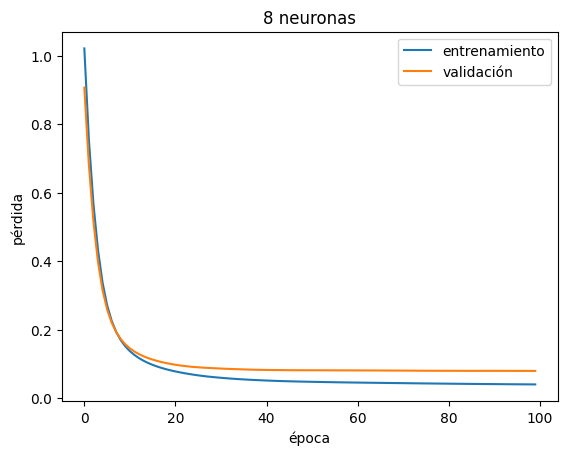

Umbral = a partir de qué probabilidad decimos «SÍ». Efecto en la VALIDACIÓN:


,umbral,acierta,precision,recall
0,0.5,0.966,0.763,0.617
1,0.3,0.973,0.766,0.766
2,0.2,0.966,0.685,0.787
3,0.1,0.958,0.600,0.830


In [23]:
modelo, hist = entrenar(neuronas=ELEGIDA)
plt.plot(hist.history["loss"], label="entrenamiento"); plt.plot(hist.history["val_loss"], label="validación")
plt.xlabel("época"); plt.ylabel("pérdida"); plt.title(f"{ELEGIDA} neuronas"); plt.legend(); plt.show()
p_val = modelo.predict(A_val, verbose=0).ravel()
print("Umbral = a partir de qué probabilidad decimos «SÍ». Efecto en la VALIDACIÓN:")
display(pd.DataFrame([dict(umbral=u, acierta=round(accuracy_score(y_val, p_val >= u), 3),
                           precision=round(precision_score(y_val, p_val >= u, zero_division=0), 3),
                           recall=round(recall_score(y_val, p_val >= u), 3)) for u in (0.5, 0.3, 0.2, 0.1)]))

### ✏️ 3 · Umbral (opcional) y métricas finales

- **precisión**: de los que la red marca «SÍ», cuántos lo eran. **recall**: de los que de verdad eran «SÍ», cuántos encuentra.
- Si fallar un «SÍ» sale caro (fraude, urgencia, incendio), bajad el umbral y decid cuánta precisión perdéis.
- La **prueba** se mira **una sola vez**: no volváis a cambiar nada después de ver estos números.

In [9]:
UMBRAL = 0.5              # ✏️ elegido mirando la tabla de validación
p = modelo.predict(A_pru, verbose=0).ravel(); c = (p >= UMBRAL).astype(int)
tn, fp, fn, tp = confusion_matrix(y_pru, c).ravel()
base_pru = max(y_pru.mean(), 1 - y_pru.mean())
print(f"""
================ FICHA PARA LA PRESENTACIÓN ================
Problema ........ predecir «{OBJETIVO}» ({ARCHIVO})
Datos ........... {len(df)} casos · {A_ent.shape[1]} entradas · {y.mean():.1%} positivos
Red ............. 1 capa oculta de {ELEGIDA} neuronas (ReLU) + salida sigmoide · Adam
Probado ......... {PRUEBAS} neuronas → val_auc {[f['val_auc'] for f in filas]}
Umbral .......... {UMBRAL}
--- PRUEBA (una sola vez) ---
Línea base ...... {base_pru:.1%}   (acertar sin red)
Exactitud ....... {accuracy_score(y_pru, c):.1%}
Precisión ....... {precision_score(y_pru, c, zero_division=0):.1%}   (de los «SÍ» que marca, cuántos lo eran)
Recall .......... {recall_score(y_pru, c):.1%}   (de los «SÍ» reales, cuántos encuentra)
AUC ............. {roc_auc_score(y_pru, p):.3f}
Casos «SÍ» reales: {tp + fn} → encuentra {tp}, se le escapan {fn}; falsas alarmas: {fp}
============================================================
""")


================ FICHA PARA LA PRESENTACIÓN ================
Problema ........ predecir «tramposo» (tramposos_juego.csv)
Datos ........... 4000 casos · 8 entradas · 5.9% positivos
Red ............. 1 capa oculta de 8 neuronas (ReLU) + salida sigmoide · Adam
Probado ......... [2, 8, 32] neuronas → val_auc [0.978, 0.981, 0.967]
Umbral .......... 0.5
--- PRUEBA (una sola vez) ---
Línea base ...... 94.1%   (acertar sin red)
Exactitud ....... 97.4%
Precisión ....... 88.2%   (de los «SÍ» que marca, cuántos lo eran)
Recall .......... 63.8%   (de los «SÍ» reales, cuántos encuentra)
AUC ............. 0.982
Casos «SÍ» reales: 47 → encuentra 30, se le escapan 17; falsas alarmas: 4



### ✏️ 4 · La aplicación: probar un caso nuevo

`probar()` coge un caso de la prueba y deja cambiar valores. Mirad las entradas disponibles con `list(X.columns)` y cambiad lo que queráis: `probar(glucosa=190)`.

In [10]:
def probar(**cambios):
    caso = X_pru.iloc[[0]].copy()
    for k, v in cambios.items(): caso[k] = v
    prob = float(modelo.predict(pre.transform(caso).astype("float32"), verbose=0).ravel()[0])
    print(caso.iloc[0].to_string(), "\n")
    print(f"Probabilidad de «{OBJETIVO}»: {prob:.0%}  →  {'SÍ' if prob >= UMBRAL else 'NO'}   (realidad de este caso: {'SÍ' if y_pru[0] else 'NO'})")

print(list(X.columns))
probar()

['precision_pct', 'headshots_pct', 'reaccion_ms', 'kd_ratio', 'horas_jugadas', 'partidas_por_dia', 'antiguedad_cuenta_dias', 'reportes_recibidos']
precision_pct              32.50
headshots_pct               2.20
reaccion_ms               271.00
kd_ratio                    1.92
horas_jugadas             601.00
partidas_por_dia            5.00
antiguedad_cuenta_dias    312.00
reportes_recibidos          2.00 

Probabilidad de «tramposo»: 0%  →  NO   (realidad de este caso: NO)


### 🔴 Extras (solo si os sobra tiempo)

**Extra 1 · Probar otro relleno de los datos que faltan** (solo tiene sentido en `diabetes_pima`, que es el único con huecos: los ceros imposibles de glucosa, presión, pliegue, insulina e IMC).

1. Subid a la celda ✏️ **1** (donde se elige el problema). Veréis dos líneas nuevas: `RELLENO` y `VALOR_FIJO`.
2. Cambiad `RELLENO`:
   - `"median"` → rellena con la **mediana** de la columna (es lo que se ha usado hasta ahora);
   - `"mean"` → rellena con la **media**;
   - `"constant"` → rellena **todas** las columnas con el mismo **valor fijo** que pongáis en `VALOR_FIJO` (probad, por ejemplo, `0` y `100`).
3. Ejecutad **otra vez desde «Preparar los datos» hasta el final** (las celdas de abajo dependen de ella). No hace falta volver a la celda de preparación inicial.
4. Anotad el `val_auc` de la tabla de ✏️ 2 con cada relleno, **con la misma lista de tamaños y las mismas semillas**: solo debe cambiar el relleno.
5. Concluid con números: ¿mejora, empeora o da igual? ¿Por qué creéis que pasa? (Pista: `"constant"` con `VALOR_FIJO = 0` equivale a no haber arreglado los ceros.)

Comparad siempre con la **validación**; la prueba se sigue mirando una sola vez, al final, con el relleno que elijáis.

### 🎤 Para la presentación

Copiad la **FICHA** de arriba, la tabla de la celda ✏️ 2 y una captura de las curvas. Preparad una frase para cada pregunta: **¿mejora la línea base? · ¿por qué ese tamaño? · ¿qué se nos escapa? · ¿lo usaríamos de verdad?**